# Lab | Time Series Analysis

## Before your start:
- Read the README.md file
- Comment as much as you can and use the resources (README.md file)
- Happy learning!

In [6]:
# Import numpy and pandas


## Challenge 1 - Loading and Evaluating The Data

In this lab, we will look at a dataset of sensor data from a cellular phone. The phone was carried in the subject's pocket for a few minutes while they walked around.

To load the data, run the code below.

In [2]:
# Run this code:

import pandas as pd

# Run this code:
sensor = pd.read_csv('../data/sub_1.csv')
sensor.drop(columns=['Unnamed: 0'], inplace=True)

Examine the data using the `head` function.

In [3]:
# Your code here:
# Show first 10 rows
sensor.head(10)

# Show first 3 rows
sensor.head(3)


,attitude.roll,attitude.pitch,attitude.yaw,gravity.x,gravity.y,gravity.z,rotationRate.x,rotationRate.y,rotationRate.z,userAcceleration.x,userAcceleration.y,userAcceleration.z
0,1.528132,-0.733896,0.696372,0.741895,0.669768,-0.031672,0.316738,0.778180,1.082764,0.294894,-0.184493,0.377542
1,1.527992,-0.716987,0.677762,0.753099,0.657116,-0.032255,0.842032,0.424446,0.643574,0.219405,0.035846,0.114866
2,1.527765,-0.706999,0.670951,0.759611,0.649555,-0.032707,-0.138143,-0.040741,0.343563,0.010714,0.134701,-0.167808


Check whether there is any missing data. If there is any missing data, remove the rows containing missing data.

In [5]:
# Check for missing values
print("Missing values:")
print(sensor.isnull().sum())

# Remove rows with any missing values and update the dataframe
original_rows = sensor.shape[0]
sensor = sensor.dropna()
new_rows = sensor.shape[0]

print(f"\nRemoved {original_rows - new_rows} rows with missing values")
print(f"New dataframe shape: {sensor.shape}")

print("Missing values after cleaning:")
print(sensor.isnull().sum().sum())  # Should be 0

Missing values:
attitude.roll         0
attitude.pitch        0
attitude.yaw          0
gravity.x             0
gravity.y             0
gravity.z             0
rotationRate.x        0
rotationRate.y        0
rotationRate.z        0
userAcceleration.x    0
userAcceleration.y    0
userAcceleration.z    0
dtype: int64

Removed 0 rows with missing values
New dataframe shape: (1751, 12)
Missing values after cleaning:
0


How many rows and columns are in our data?

In [6]:
# Get the number of rows and columns
print(f"The dataset has {sensor.shape[0]} rows and {sensor.shape[1]} columns")

# Or you can unpack the shape tuple
rows, columns = sensor.shape
print(f"Rows: {rows}")
print(f"Columns: {columns}")



The dataset has 1751 rows and 12 columns
Rows: 1751
Columns: 12


To perform time series analysis on the data, we must change the index from a range index to a time series index. In the cell below, create a time series index using the `pd.date_range` function. Create a time series index starting at 1/1/2018 00:00:00 and ending at 1/1/2018 00:29:10. The number of periods is equal to the number of rows in `sensor`. The frequency should be set to `infer`.

In [7]:
# Create time index with inferred frequency
time_index = pd.date_range(start='1/1/2018 00:00:00', end='1/1/2018 00:29:10', periods=len(sensor))

# Set the time index
sensor.index = time_index

# Display information about the new index
print("First few index values:")
print(sensor.index[:5])
print("\nLast few index values:")
print(sensor.index[-5:])
print(f"\nIndex frequency: {sensor.index.freq}")



First few index values:
DatetimeIndex(['2018-01-01 00:00:00', '2018-01-01 00:00:01',
               '2018-01-01 00:00:02', '2018-01-01 00:00:03',
               '2018-01-01 00:00:04'],
              dtype='datetime64[ns]', freq=None)

Last few index values:
DatetimeIndex(['2018-01-01 00:29:06', '2018-01-01 00:29:07',
               '2018-01-01 00:29:08', '2018-01-01 00:29:09',
               '2018-01-01 00:29:10'],
              dtype='datetime64[ns]', freq=None)

Index frequency: None


Assign the time series index to the dataframe's index.

In [8]:
# First, let's verify that the time series index is now set
print("DataFrame index type:", type(sensor.index))
print("\nFirst few rows with the new time index:")
print(sensor.head())

print("\nIndex information:")
print("Start time:", sensor.index[0])
print("End time:", sensor.index[-1])
print("Number of time points:", len(sensor.index))



DataFrame index type: <class 'pandas.core.indexes.datetimes.DatetimeIndex'>

First few rows with the new time index:
                     attitude.roll  attitude.pitch  attitude.yaw  gravity.x  \
2018-01-01 00:00:00       1.528132       -0.733896      0.696372   0.741895   
2018-01-01 00:00:01       1.527992       -0.716987      0.677762   0.753099   
2018-01-01 00:00:02       1.527765       -0.706999      0.670951   0.759611   
2018-01-01 00:00:03       1.516768       -0.704678      0.675735   0.760709   
2018-01-01 00:00:04       1.493941       -0.703918      0.672994   0.760062   

                     gravity.y  gravity.z  rotationRate.x  rotationRate.y  \
2018-01-01 00:00:00   0.669768  -0.031672        0.316738        0.778180   
2018-01-01 00:00:01   0.657116  -0.032255        0.842032        0.424446   
2018-01-01 00:00:02   0.649555  -0.032707       -0.138143       -0.040741   
2018-01-01 00:00:03   0.647788  -0.041140       -0.025005       -1.048717   
2018-01-01 00:00:04   0

Our next step is to decompose the time series and evaluate the patterns in the data. Load the `statsmodels.api` submodule and plot the decomposed plot of `userAcceleration.x`. Set `freq=60` in the `seasonal_decompose` function. Your graph should look like the one below.

![time series decomposition](./images/tsa_decompose.png)

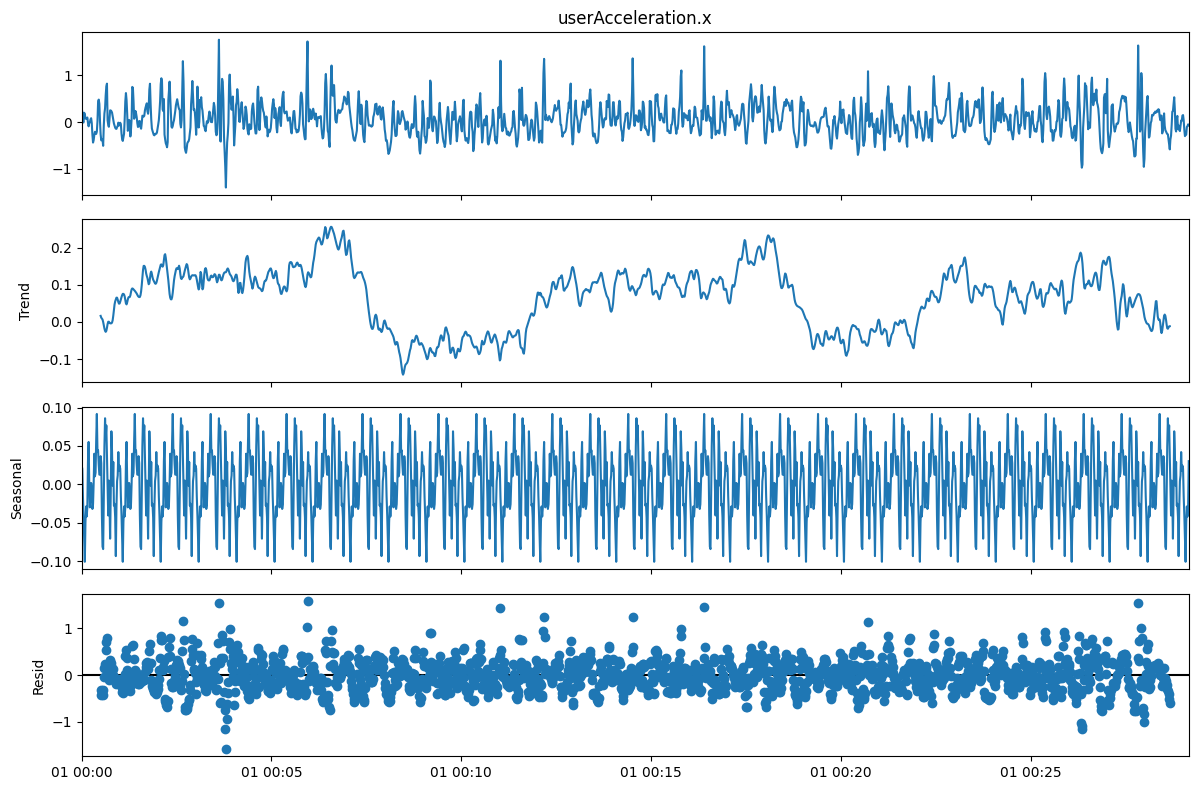

In [12]:
import statsmodels.api as sm
import matplotlib.pyplot as plt

# Decompose the time series using 'period' instead of 'freq'
decomposition = sm.tsa.seasonal_decompose(sensor['userAcceleration.x'], model='additive', period=60)

# Plot the decomposed components
fig = decomposition.plot()
fig.set_size_inches(12, 8)
plt.tight_layout()
plt.show()




Plot the decomposed time series of `rotationRate.x` also with a frequency of 60.

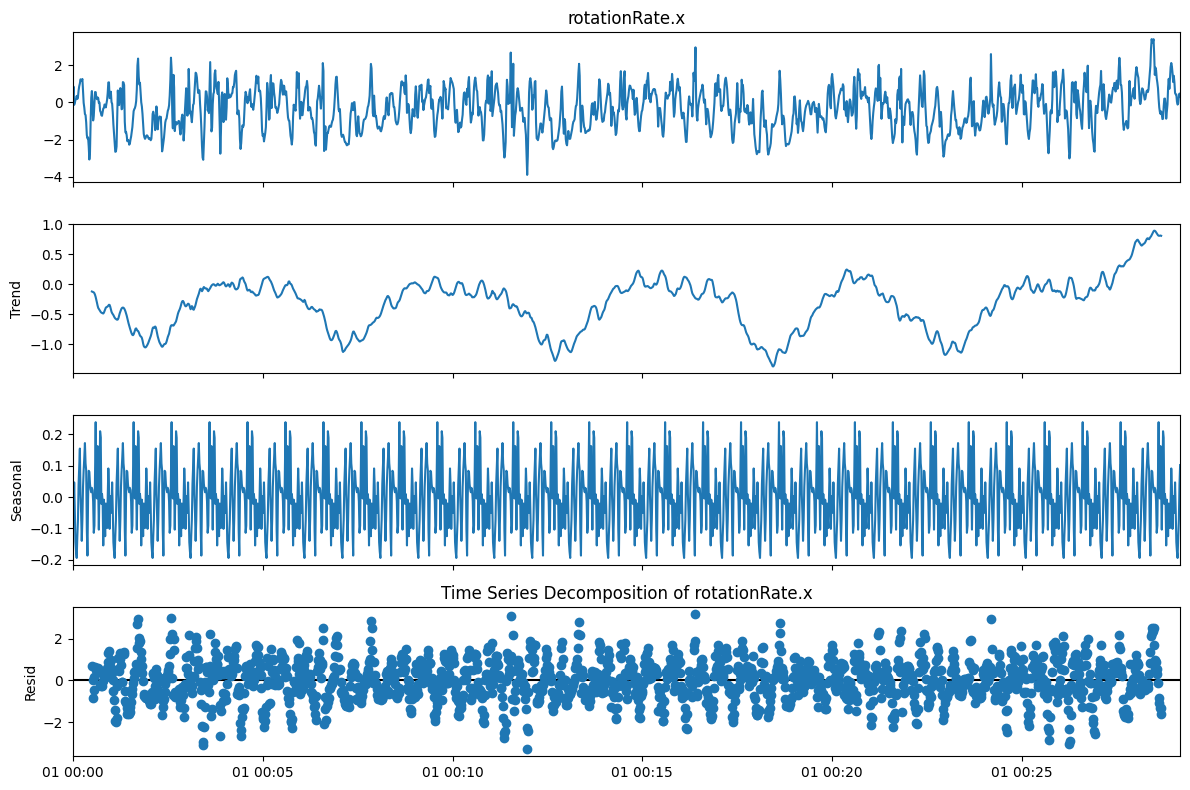

In [13]:
# Decompose the time series for rotationRate.x
decomposition_rotation = sm.tsa.seasonal_decompose(sensor['rotationRate.x'], model='additive', period=60)

# Plot the decomposed components
fig = decomposition_rotation.plot()
fig.set_size_inches(12, 8)
plt.title('Time Series Decomposition of rotationRate.x')
plt.tight_layout()
plt.show()

## Challenge 2 - Modelling the Data

To model our data, we should look at a few assumptions. First, let's plot the `lag_plot` to detect any autocorrelation. Do this for `userAcceleration.x`

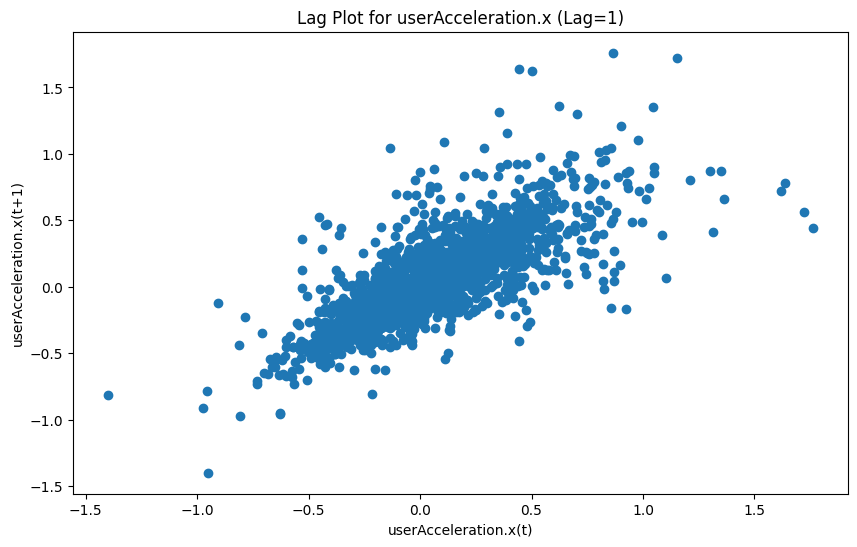

In [14]:
from pandas.plotting import lag_plot

# Create lag plot for userAcceleration.x
plt.figure(figsize=(10, 6))
lag_plot(sensor['userAcceleration.x'], lag=1)
plt.title('Lag Plot for userAcceleration.x (Lag=1)')
plt.xlabel('userAcceleration.x(t)')
plt.ylabel('userAcceleration.x(t+1)')
plt.show()



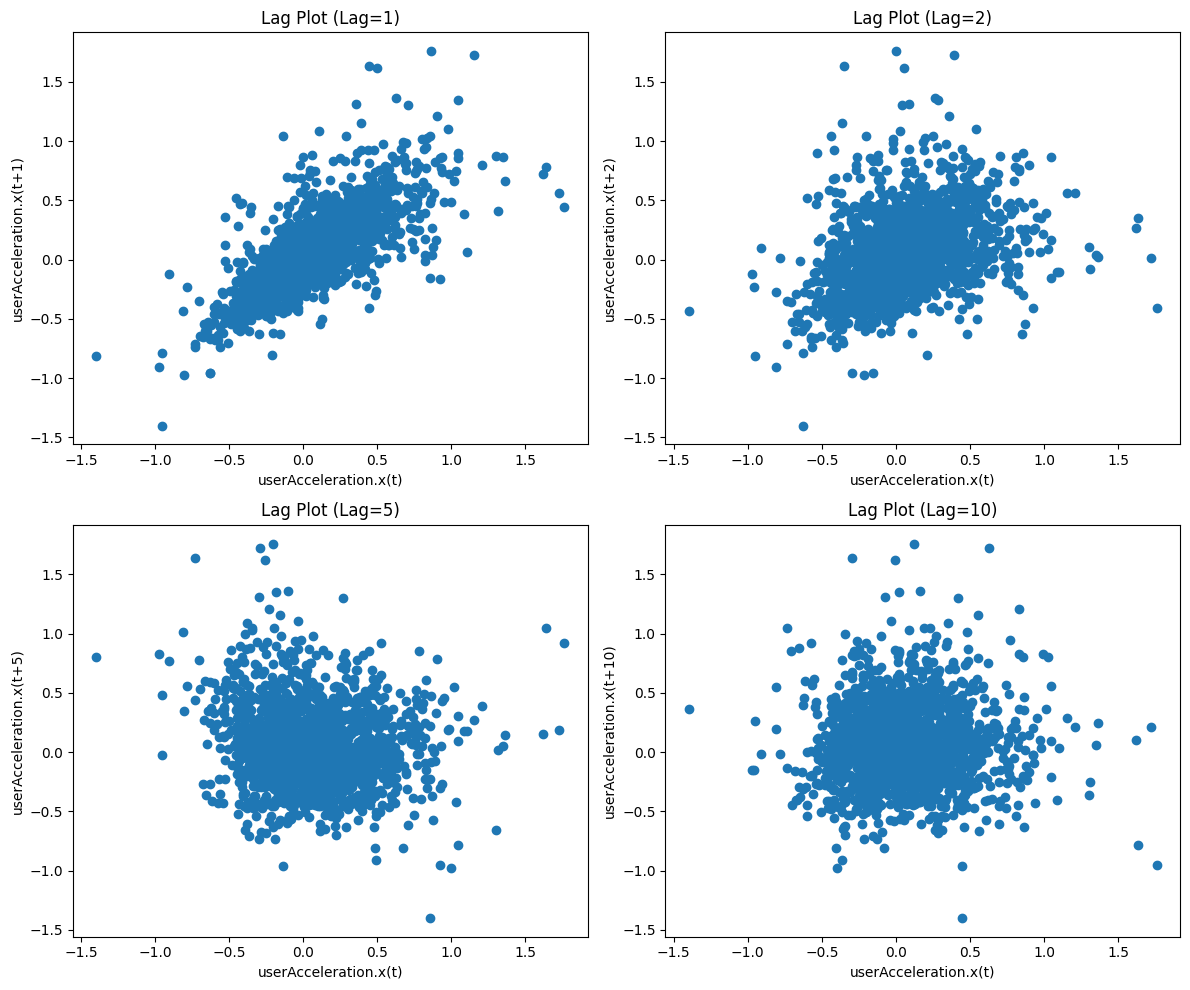

In [15]:
# I'm intrigued - so here's multiple lag plots for different lags
lags = [1, 2, 5, 10]  # Different time lags to check

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.ravel()

for i, lag in enumerate(lags):
    lag_plot(sensor['userAcceleration.x'], lag=lag, ax=axes[i])
    axes[i].set_title(f'Lag Plot (Lag={lag})')
    axes[i].set_xlabel(f'userAcceleration.x(t)')
    axes[i].set_ylabel(f'userAcceleration.x(t+{lag})')

plt.tight_layout()
plt.show()

Create a lag plot for `rotationRate.x`

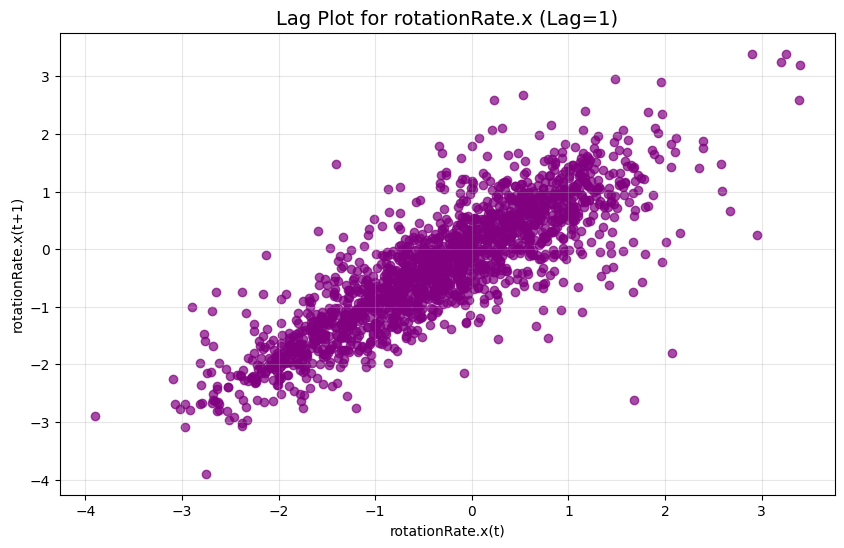

In [16]:
from pandas.plotting import lag_plot

# Create lag plot for rotationRate.x with purple color
plt.figure(figsize=(10, 6))
lag_plot(sensor['rotationRate.x'], lag=1, c='purple', alpha=0.7)
plt.title('Lag Plot for rotationRate.x (Lag=1)', fontsize=14)
plt.xlabel('rotationRate.x(t)')
plt.ylabel('rotationRate.x(t+1)')
plt.grid(True, alpha=0.3)
plt.show()



What are your conclusions from both visualizations?

Comparative Insights:
Different time-related dependencies - Acceleration has stronger short-term memory than rotation

Physical movement interpretation - Linear movements (acceleration) show more persistence than rotational movements

Modeling implications - May need different approaches: AR models for acceleration vs. potentially more complex models for rotation

Sensor behavior - Suggests different types of human motion patterns captured by each sensor type

These patterns reflect real physical behaviors where linear momentum tends to persist more continuously, while rotational movements can be more abrupt and change direction quickly.

In [16]:
# Your conclusions here:



The next step will be to test both variables for stationarity. Perform the Augmented Dickey Fuller test on both variables below.

In [17]:
from statsmodels.tsa.stattools import adfuller

# Perform ADF test on userAcceleration.x
print("Augmented Dickey-Fuller Test for userAcceleration.x:")
result_accel = adfuller(sensor['userAcceleration.x'])
print(f'ADF Statistic: {result_accel[0]:.6f}')
print(f'p-value: {result_accel[1]:.6f}')
print('Critical Values:')
for key, value in result_accel[4].items():
    print(f'\t{key}: {value:.6f}')

if result_accel[1] < 0.05:
    print("Result: Stationary (reject null hypothesis)")
else:
    print("Result: Non-stationary (fail to reject null hypothesis)")

print("\n" + "="*50 + "\n")

# Perform ADF test on rotationRate.x
print("Augmented Dickey-Fuller Test for rotationRate.x:")
result_rotation = adfuller(sensor['rotationRate.x'])
print(f'ADF Statistic: {result_rotation[0]:.6f}')
print(f'p-value: {result_rotation[1]:.6f}')
print('Critical Values:')
for key, value in result_rotation[4].items():
    print(f'\t{key}: {value:.6f}')

if result_rotation[1] < 0.05:
    print("Result: Stationary (reject null hypothesis)")
else:
    print("Result: Non-stationary (fail to reject null hypothesis)")



Augmented Dickey-Fuller Test for userAcceleration.x:
ADF Statistic: -17.957994
p-value: 0.000000
Critical Values:
	1%: -3.434101
	5%: -2.863197
	10%: -2.567652
Result: Stationary (reject null hypothesis)


Augmented Dickey-Fuller Test for rotationRate.x:
ADF Statistic: -5.269861
p-value: 0.000006
Critical Values:
	1%: -3.434147
	5%: -2.863217
	10%: -2.567663
Result: Stationary (reject null hypothesis)


What are your conclusions from this test?

In [ ]:
# # Your conclusions here:
# The test tells us whether the underlying data generation process is stable over time, which is crucial for choosing 
# appropriate forecasting models and ensuring reliable predictions.



Finally, we'll create an ARMA model for `userAcceleration.x`. Load the `ARMA` function from `statsmodels`. The order of the model is (2, 1). Split the data to train and test. Use the last 10 observations as the test set and all other observations as the training set. 

In [20]:
from statsmodels.tsa.api import ARIMA
import numpy as np

# Split the data into train and test sets
train_data = sensor['userAcceleration.x'][:-10]  # All except last 10 observations
test_data = sensor['userAcceleration.x'][-10:]   # Last 10 observations

print(f"Training set size: {len(train_data)}")
print(f"Test set size: {len(test_data)}")
print(f"Total observations: {len(sensor)}")

# Create and fit ARMA(2,1) model using ARIMA with d=0
# ARIMA(p=2, d=0, q=1) is equivalent to ARMA(2,1)
model = ARIMA(train_data, order=(2, 0, 1))
fitted_model = model.fit()

# Display model summary
print("\nARMA(2,1) Model Summary:")
print(fitted_model.summary())

# Generate predictions for the test set
predictions = fitted_model.predict(start=len(train_data), end=len(train_data)+len(test_data)-1)

print("\nPredictions vs Actual Values:")
for i, (pred, actual) in enumerate(zip(predictions, test_data)):
    print(f"Step {i+1}: Predicted = {pred:.4f}, Actual = {actual:.4f}")

# Calculate prediction error
mse = np.mean((predictions - test_data) ** 2)
rmse = np.sqrt(mse)
mae = np.mean(np.abs(predictions - test_data))

print(f"\nModel Performance Metrics:")
print(f"Mean Squared Error (MSE): {mse:.6f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.6f}")
print(f"Mean Absolute Error (MAE): {mae:.6f}")





Training set size: 1741
Test set size: 10
Total observations: 1751

ARMA(2,1) Model Summary:


c:\Users\profe\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency s will be used.
  self._init_dates(dates, freq)
c:\Users\profe\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency s will be used.
  self._init_dates(dates, freq)
c:\Users\profe\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency s will be used.
  self._init_dates(dates, freq)


                               SARIMAX Results                                
Dep. Variable:     userAcceleration.x   No. Observations:                 1741
Model:                 ARIMA(2, 0, 1)   Log Likelihood                 373.401
Date:                Mon, 06 Oct 2025   AIC                           -736.803
Time:                        11:13:25   BIC                           -709.492
Sample:                    01-01-2018   HQIC                          -726.704
                         - 01-01-2018                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0637      0.016      3.994      0.000       0.032       0.095
ar.L1          0.9882      0.036     27.630      0.000       0.918       1.058
ar.L2         -0.3788      0.033    -11.637      0.0

To compare our predictions with the observed data, we can compute the RMSE (Root Mean Squared Error) from the submodule `statsmodels.tools.eval_measures`. You can read more about this function [here](https://www.statsmodels.org/dev/generated/statsmodels.tools.eval_measures.rmse.html). Compute the RMSE for the last 10 rows of the data by comparing the observed and predicted data for the `userAcceleration.x` column.

In [21]:
from statsmodels.tools.eval_measures import rmse

# Calculate RMSE using statsmodels
rmse_value = rmse(test_data, predictions)

print(f"Root Mean Squared Error (RMSE) for userAcceleration.x predictions:")
print(f"RMSE: {rmse_value:.6f}")

# You can also compare with manually calculated RMSE to verify
manual_rmse = np.sqrt(np.mean((test_data - predictions) ** 2))
print(f"Manual RMSE calculation: {manual_rmse:.6f}")
print(f"Both methods match: {np.isclose(rmse_value, manual_rmse)}")

# Display the comparison in a table
print("\nDetailed comparison:")
print("Index | Actual    | Predicted  | Error     | Squared Error")
print("-" * 55)
for i, (actual, pred) in enumerate(zip(test_data, predictions)):
    error = actual - pred
    sq_error = error ** 2
    print(f"{i:5} | {actual:8.4f} | {pred:8.4f} | {error:8.4f} | {sq_error:8.4f}")

print(f"\nSum of Squared Errors: {np.sum((test_data - predictions) ** 2):.6f}")
print(f"Mean Squared Error: {np.mean((test_data - predictions) ** 2):.6f}")
print(f"Root Mean Squared Error: {rmse_value:.6f}")



Root Mean Squared Error (RMSE) for userAcceleration.x predictions:
RMSE: 0.225292
Manual RMSE calculation: 0.225292
Both methods match: True

Detailed comparison:
Index | Actual    | Predicted  | Error     | Squared Error
-------------------------------------------------------
    0 |   0.1497 |   0.1731 |  -0.0234 |   0.0005
    1 |   0.0385 |   0.1429 |  -0.1044 |   0.0109
    2 |  -0.1692 |   0.1005 |  -0.2697 |   0.0727
    3 |  -0.3004 |   0.0701 |  -0.3705 |   0.1372
    4 |  -0.2702 |   0.0561 |  -0.3263 |   0.1064
    5 |  -0.2684 |   0.0538 |  -0.3221 |   0.1038
    6 |  -0.1024 |   0.0568 |  -0.1592 |   0.0254
    7 |  -0.0856 |   0.0606 |  -0.1462 |   0.0214
    8 |  -0.0481 |   0.0633 |  -0.1114 |   0.0124
    9 |  -0.0650 |   0.0645 |  -0.1295 |   0.0168

Sum of Squared Errors: 0.507563
Mean Squared Error: 0.050756
Root Mean Squared Error: 0.225292
